# Loader & Transform Visualization
Visualize the output of `loader.py` — raw data, each transform stage, and final dataset output.

In [3]:
import os
import sys
import numpy as np
import torch
import nibabel as nib
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from monai.transforms import (
    Compose, LoadImaged, EnsureChannelFirstd, Orientationd,
    RandFlipd, RandRotate90d, RandAffined, RandGaussianNoised, RandAdjustContrastd,
)

# Add project root to path
sys.path.insert(0, os.path.dirname(os.path.abspath('__file__')))
from loader import MonaiNiftiSliceDataset, get_monai_nifti_transforms


def collect_data_files(data_path, mr_pattern="mr.nii", ct_pattern="ct.nii",
                       mask_pattern="mask.nii", use_body_mask=False):
    """Collect MR, CT, and optionally mask file pairs from directory structure."""
    data_files = []
    if not os.path.exists(data_path):
        raise FileNotFoundError(f"Data path not found: {data_path}")
    for patient_dir in sorted(os.listdir(data_path)):
        patient_path = os.path.join(data_path, patient_dir)
        if not os.path.isdir(patient_path):
            continue
        mr_file, ct_file, mask_file = None, None, None
        for filename in os.listdir(patient_path):
            if mr_pattern in filename:
                mr_file = os.path.join(patient_path, filename)
            if ct_pattern in filename:
                ct_file = os.path.join(patient_path, filename)
            if use_body_mask and mask_pattern in filename:
                mask_file = os.path.join(patient_path, filename)
        if mr_file and ct_file:
            entry = {"mr": mr_file, "ct": ct_file, "id": patient_dir}
            if use_body_mask:
                entry["mask"] = mask_file
                if mask_file is None:
                    print(f"Warning: No mask found for patient {patient_dir}")
            data_files.append(entry)
    return data_files


%matplotlib inline
plt.rcParams['figure.dpi'] = 120

## 1. Configuration

In [4]:
DATA_DIR = "/mnt/nvme/lloyd/DL project CT-MRI/pfgm_train_brain_new"
MR_PATTERN = "mr.nii"
CT_PATTERN = "ct.nii"
MASK_PATTERN = "mask.nii"
USE_BODY_MASK = True
TARGET_SIZE = 256
SLICE_IDX = None  # Set to int to pick a specific slice, or None for middle slice

## 2. Collect Files & Pick a Patient

In [5]:
# Collect all patient file dicts
all_files = collect_data_files(
    DATA_DIR, mr_pattern=MR_PATTERN, ct_pattern=CT_PATTERN,
    mask_pattern=MASK_PATTERN, use_body_mask=USE_BODY_MASK,
)
print(f"Found {len(all_files)} patients")

# Pick first patient
sample = all_files[0]
print(f"Patient: {sample['id']}")
print(f"  MR:   {sample['mr']}")
print(f"  CT:   {sample['ct']}")
print(f"  Mask: {sample.get('mask', 'N/A')}")

Found 303 patients
Patient: 1BA001
  MR:   /mnt/nvme/lloyd/DL project CT-MRI/pfgm_train_brain_new/1BA001/mr.nii_processed_patch.nii.gz
  CT:   /mnt/nvme/lloyd/DL project CT-MRI/pfgm_train_brain_new/1BA001/ct.nii_processed_patch.nii.gz
  Mask: /mnt/nvme/lloyd/DL project CT-MRI/pfgm_train_brain_new/1BA001/mask.nii_processed_patch.nii.gz


## 3. Raw NIfTI Data (before any transforms)

MR shape: (231, 244, 163), range: [-1.000, 1.000]
CT shape: (231, 244, 163), range: [-0.999, 1.000]
Mask shape: (231, 244, 163), unique: [0. 1.]

Visualization slice index: 81


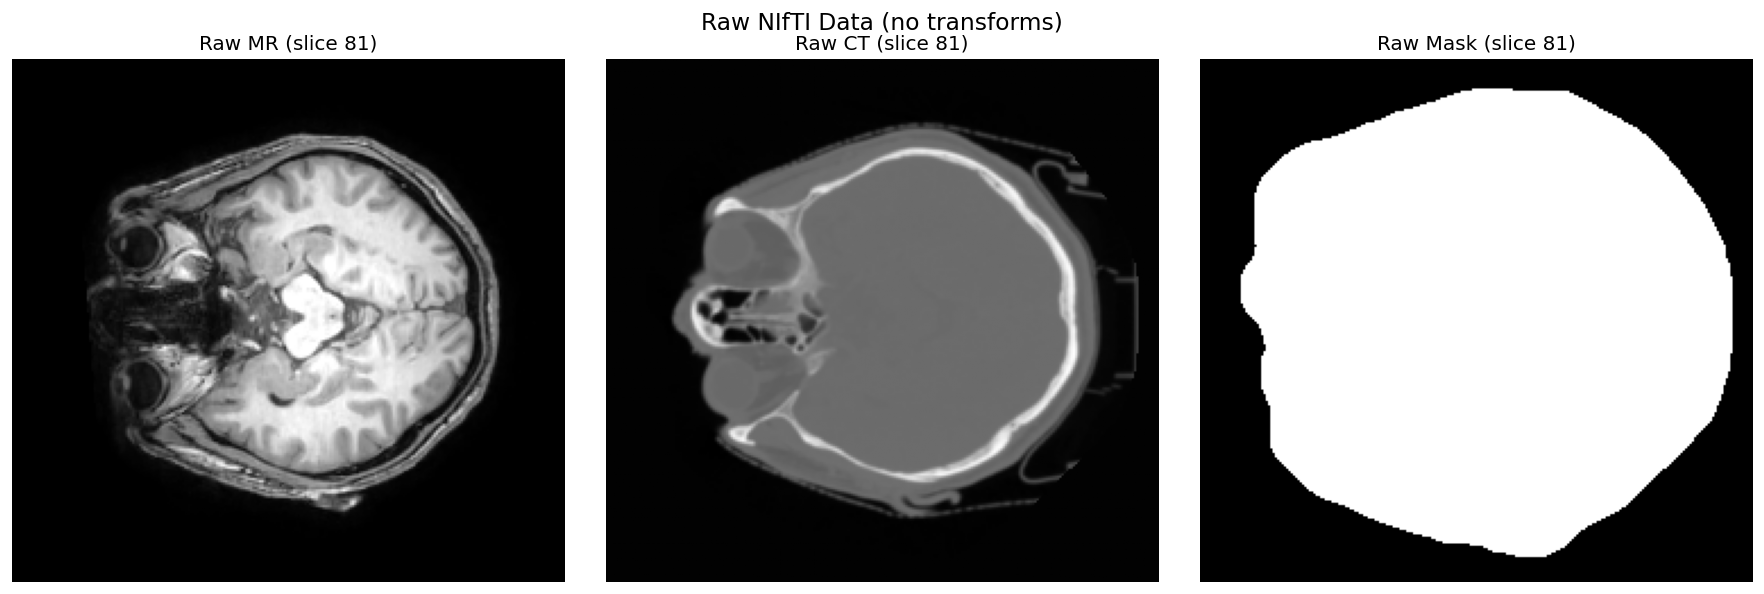

In [6]:
# Load raw volumes with nibabel
mr_nii = nib.load(sample['mr'])
ct_nii = nib.load(sample['ct'])
mr_raw = mr_nii.get_fdata()
ct_raw = ct_nii.get_fdata()

has_mask = sample.get('mask') is not None
if has_mask:
    mask_nii = nib.load(sample['mask'])
    mask_raw = mask_nii.get_fdata()

print(f"MR shape: {mr_raw.shape}, range: [{mr_raw.min():.3f}, {mr_raw.max():.3f}]")
print(f"CT shape: {ct_raw.shape}, range: [{ct_raw.min():.3f}, {ct_raw.max():.3f}]")
if has_mask:
    print(f"Mask shape: {mask_raw.shape}, unique: {np.unique(mask_raw)}")

# Pick slice
s = SLICE_IDX if SLICE_IDX is not None else mr_raw.shape[-1] // 2
print(f"\nVisualization slice index: {s}")

ncols = 3 if has_mask else 2
fig, axes = plt.subplots(1, ncols, figsize=(5 * ncols, 5))
axes[0].imshow(mr_raw[:, :, s], cmap='gray'); axes[0].set_title(f'Raw MR (slice {s})')
axes[1].imshow(ct_raw[:, :, s], cmap='gray'); axes[1].set_title(f'Raw CT (slice {s})')
if has_mask:
    axes[2].imshow(mask_raw[:, :, s], cmap='gray'); axes[2].set_title(f'Raw Mask (slice {s})')
for ax in axes: ax.axis('off')
plt.suptitle('Raw NIfTI Data (no transforms)', fontsize=14)
plt.tight_layout(); plt.show()

## 4. Step-by-Step Transform Visualization
Apply each transform stage individually to see its effect.

In [8]:
keys = ["mr", "ct", "mask"] if USE_BODY_MASK else ["mr", "ct"]
resize_modes = ["bilinear", "bilinear"] + (["nearest"] if USE_BODY_MASK else [])

# Build transform input dict (filter None mask)
transform_input = {"mr": sample["mr"], "ct": sample["ct"]}
if USE_BODY_MASK and sample.get("mask") is not None:
    transform_input["mask"] = sample["mask"]

# Define individual transform stages
stages = [
    ("1. LoadImaged", Compose([
        LoadImaged(keys=keys, image_only=True, allow_missing_keys=True),
    ])),
    ("2. + EnsureChannelFirst", Compose([
        LoadImaged(keys=keys, image_only=True, allow_missing_keys=True),
        EnsureChannelFirstd(keys=keys, allow_missing_keys=True),
    ])),
    ("3. + Orientationd (RAS)", Compose([
        LoadImaged(keys=keys, image_only=True, allow_missing_keys=True),
        EnsureChannelFirstd(keys=keys, allow_missing_keys=True),
        Orientationd(keys=keys, axcodes="RAS", allow_missing_keys=True),
    ])),
    ("4. + RandFlipd (H, prob=1)", Compose([
        LoadImaged(keys=keys, image_only=True, allow_missing_keys=True),
        EnsureChannelFirstd(keys=keys, allow_missing_keys=True),
        Orientationd(keys=keys, axcodes="RAS", allow_missing_keys=True),
        RandFlipd(keys=keys, prob=1.0, spatial_axis=0, allow_missing_keys=True),
    ])),
    ("5. + RandFlipd (W, prob=1)", Compose([
        LoadImaged(keys=keys, image_only=True, allow_missing_keys=True),
        EnsureChannelFirstd(keys=keys, allow_missing_keys=True),
        Orientationd(keys=keys, axcodes="RAS", allow_missing_keys=True),
        RandFlipd(keys=keys, prob=1.0, spatial_axis=0, allow_missing_keys=True),
        RandFlipd(keys=keys, prob=1.0, spatial_axis=1, allow_missing_keys=True),
    ])),
    ("6. + RandRotate90d (prob=1)", Compose([
        LoadImaged(keys=keys, image_only=True, allow_missing_keys=True),
        EnsureChannelFirstd(keys=keys, allow_missing_keys=True),
        Orientationd(keys=keys, axcodes="RAS", allow_missing_keys=True),
        RandFlipd(keys=keys, prob=1.0, spatial_axis=0, allow_missing_keys=True),
        RandFlipd(keys=keys, prob=1.0, spatial_axis=1, allow_missing_keys=True),
        RandRotate90d(keys=keys, prob=1.0, spatial_axes=(0, 1), allow_missing_keys=True),
    ])),
    ("7. + RandAffined (prob=1)", Compose([
        LoadImaged(keys=keys, image_only=True, allow_missing_keys=True),
        EnsureChannelFirstd(keys=keys, allow_missing_keys=True),
        Orientationd(keys=keys, axcodes="RAS", allow_missing_keys=True),
        RandFlipd(keys=keys, prob=1.0, spatial_axis=0, allow_missing_keys=True),
        RandFlipd(keys=keys, prob=1.0, spatial_axis=1, allow_missing_keys=True),
        RandRotate90d(keys=keys, prob=1.0, spatial_axes=(0, 1), allow_missing_keys=True),
        RandAffined(keys=keys, prob=1.0,
                    rotate_range=(0.0, 0.0, np.deg2rad(5.0)),
                    scale_range=(0.05, 0.05, 0.0),
                    mode=resize_modes, padding_mode="border",
                    allow_missing_keys=True),
    ])),
    ("8. + GaussianNoise (prob=1)", Compose([
        LoadImaged(keys=keys, image_only=True, allow_missing_keys=True),
        EnsureChannelFirstd(keys=keys, allow_missing_keys=True),
        Orientationd(keys=keys, axcodes="RAS", allow_missing_keys=True),
        RandFlipd(keys=keys, prob=1.0, spatial_axis=0, allow_missing_keys=True),
        RandFlipd(keys=keys, prob=1.0, spatial_axis=1, allow_missing_keys=True),
        RandRotate90d(keys=keys, prob=1.0, spatial_axes=(0, 1), allow_missing_keys=True),
        RandAffined(keys=keys, prob=1.0,
                    rotate_range=(0.0, 0.0, np.deg2rad(5.0)),
                    scale_range=(0.05, 0.05, 0.0),
                    mode=resize_modes, padding_mode="border",
                    allow_missing_keys=True),
        RandGaussianNoised(keys=["mr"], prob=1.0, mean=0.0, std=0.02),
    ])),
    ("9. + AdjustContrast (prob=1)", Compose([
        LoadImaged(keys=keys, image_only=True, allow_missing_keys=True),
        EnsureChannelFirstd(keys=keys, allow_missing_keys=True),
        Orientationd(keys=keys, axcodes="RAS", allow_missing_keys=True),
        RandFlipd(keys=keys, prob=1.0, spatial_axis=0, allow_missing_keys=True),
        RandFlipd(keys=keys, prob=1.0, spatial_axis=1, allow_missing_keys=True),
        RandRotate90d(keys=keys, prob=1.0, spatial_axes=(0, 1), allow_missing_keys=True),
        RandAffined(keys=keys, prob=1.0,
                    rotate_range=(0.0, 0.0, np.deg2rad(5.0)),
                    scale_range=(0.05, 0.05, 0.0),
                    mode=resize_modes, padding_mode="border",
                    allow_missing_keys=True),
        RandGaussianNoised(keys=["mr"], prob=1.0, mean=0.0, std=0.02),
        RandAdjustContrastd(keys=["mr"], prob=1.0, gamma=(0.9, 1.1)),
    ])),
]

print(f"Running {len(stages)} transform stages...")

Running 9 transform stages...


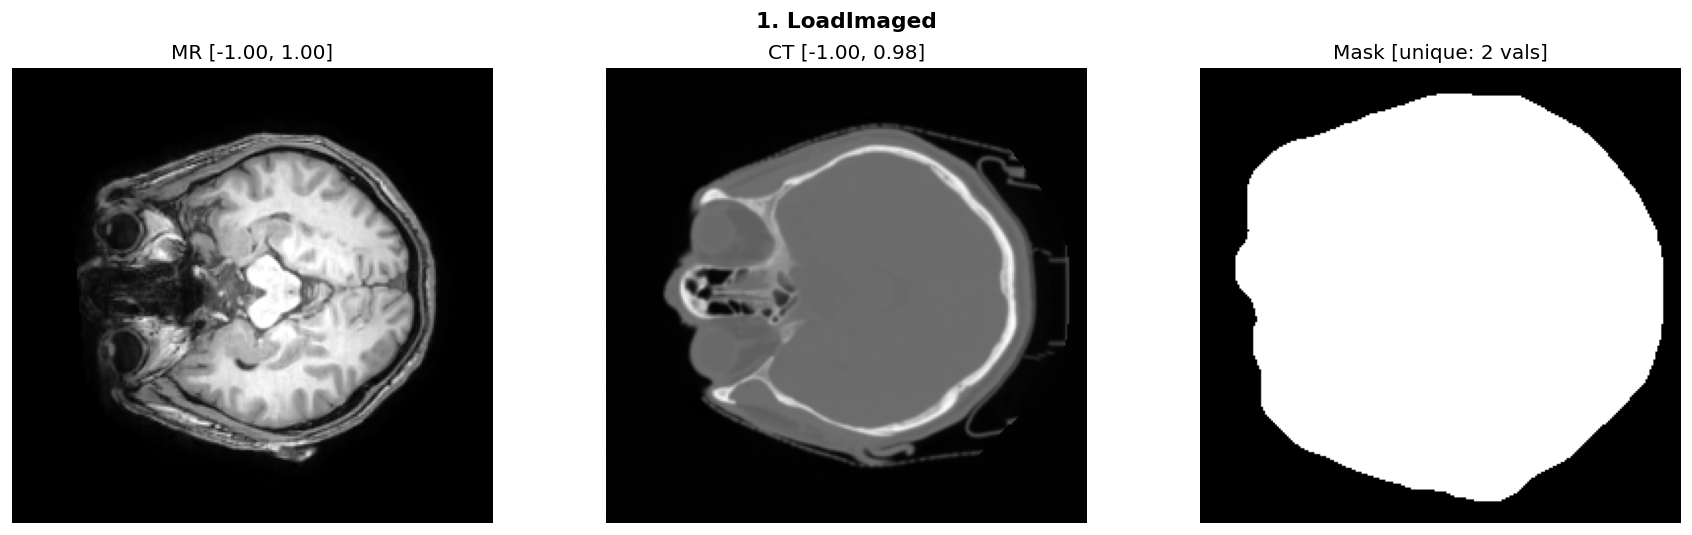

  MR shape: torch.Size([231, 244, 163]), CT shape: torch.Size([231, 244, 163])



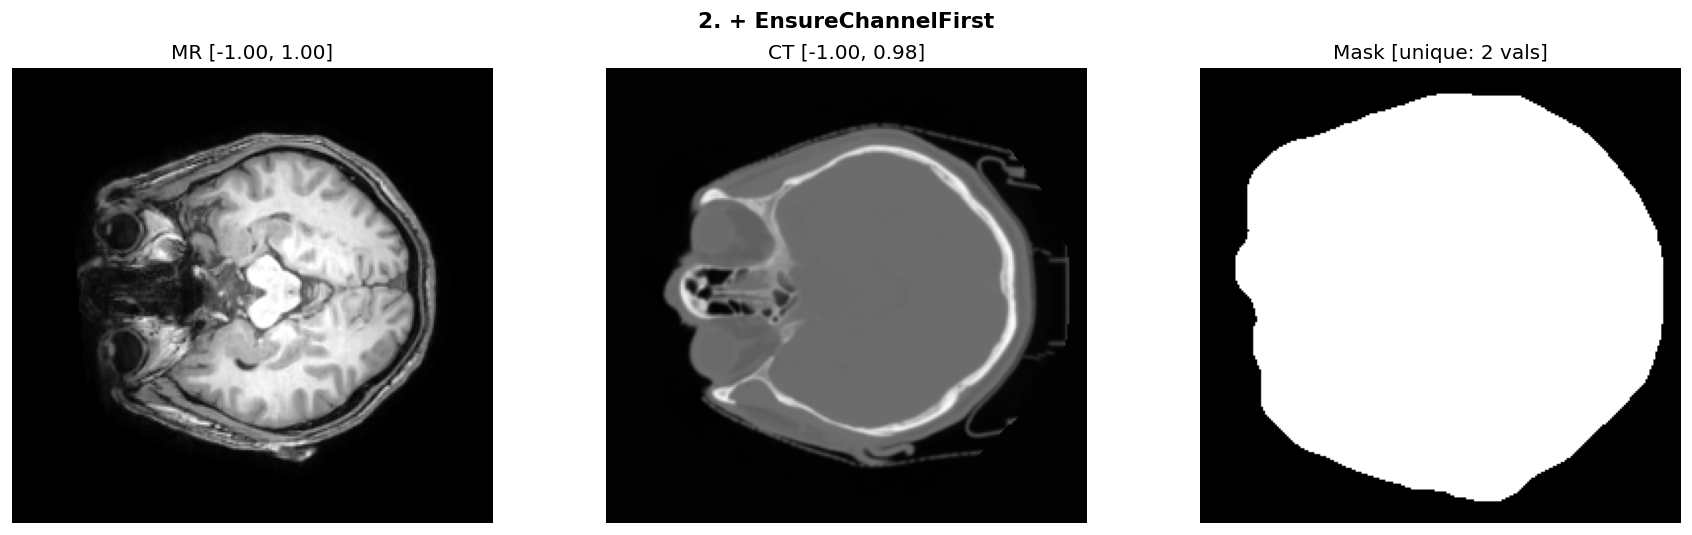

  MR shape: torch.Size([1, 231, 244, 163]), CT shape: torch.Size([1, 231, 244, 163])



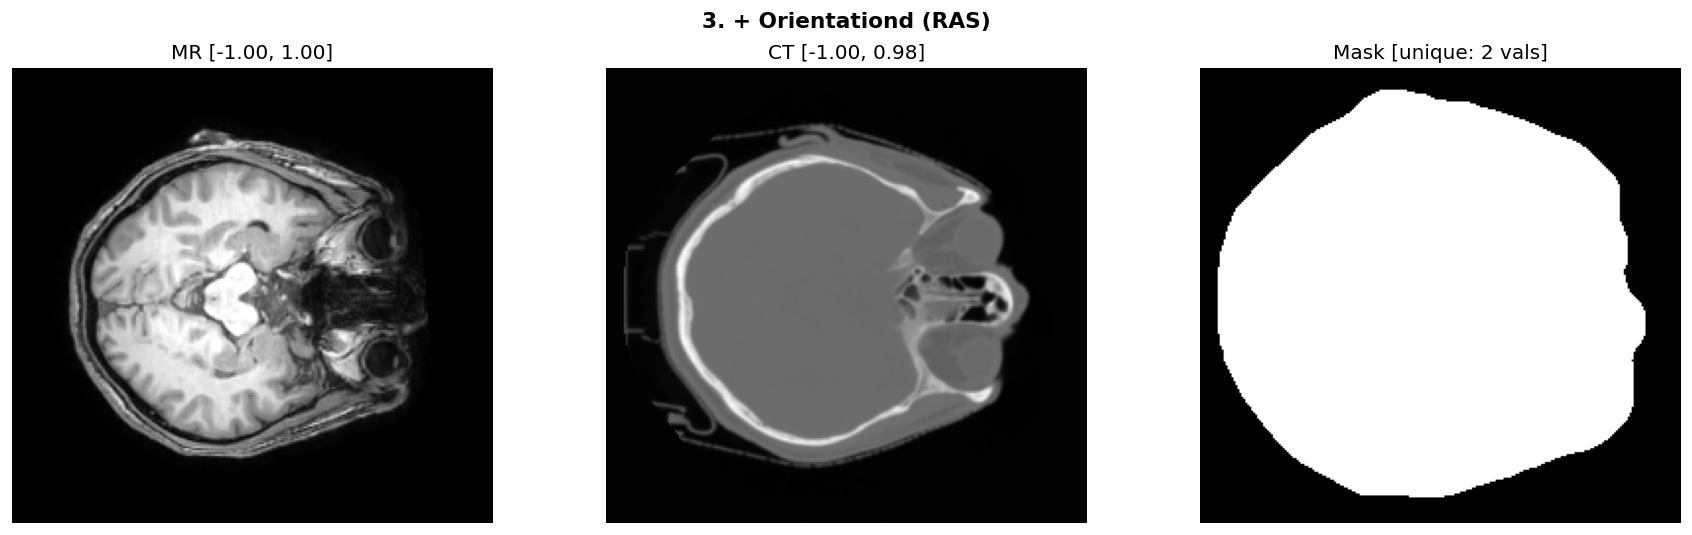

  MR shape: torch.Size([1, 231, 244, 163]), CT shape: torch.Size([1, 231, 244, 163])



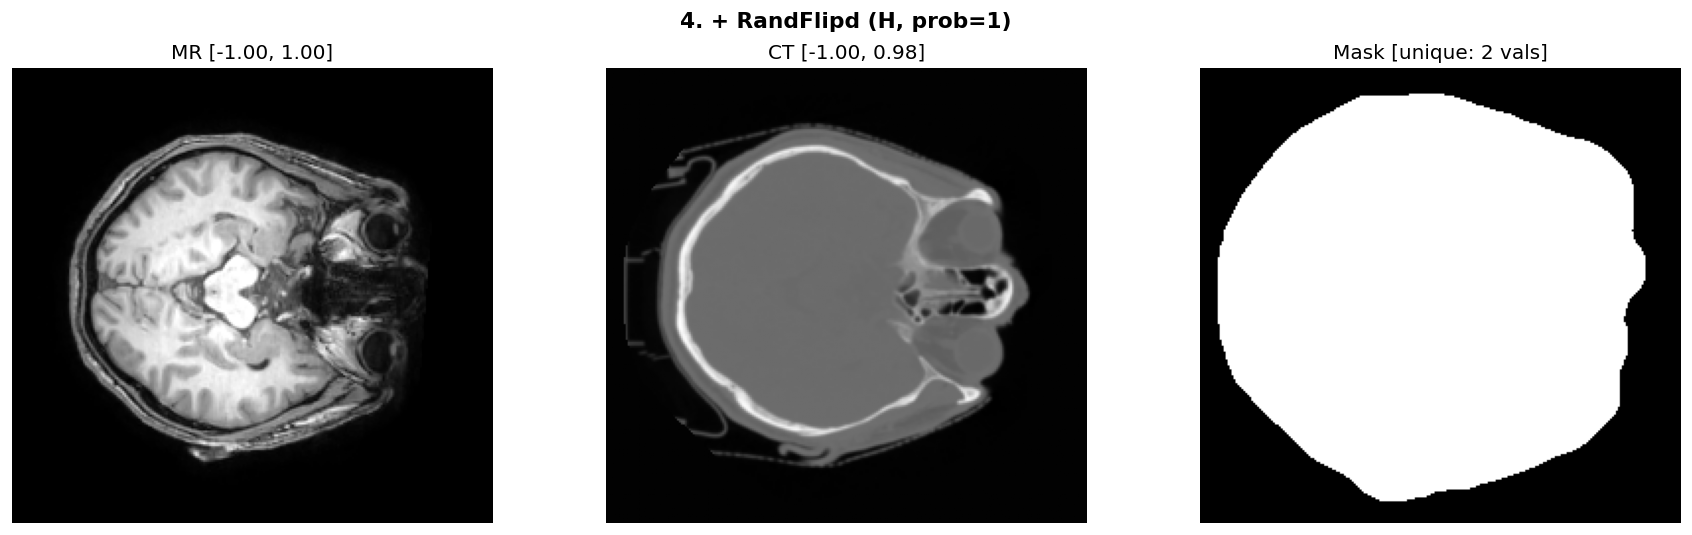

  MR shape: torch.Size([1, 231, 244, 163]), CT shape: torch.Size([1, 231, 244, 163])



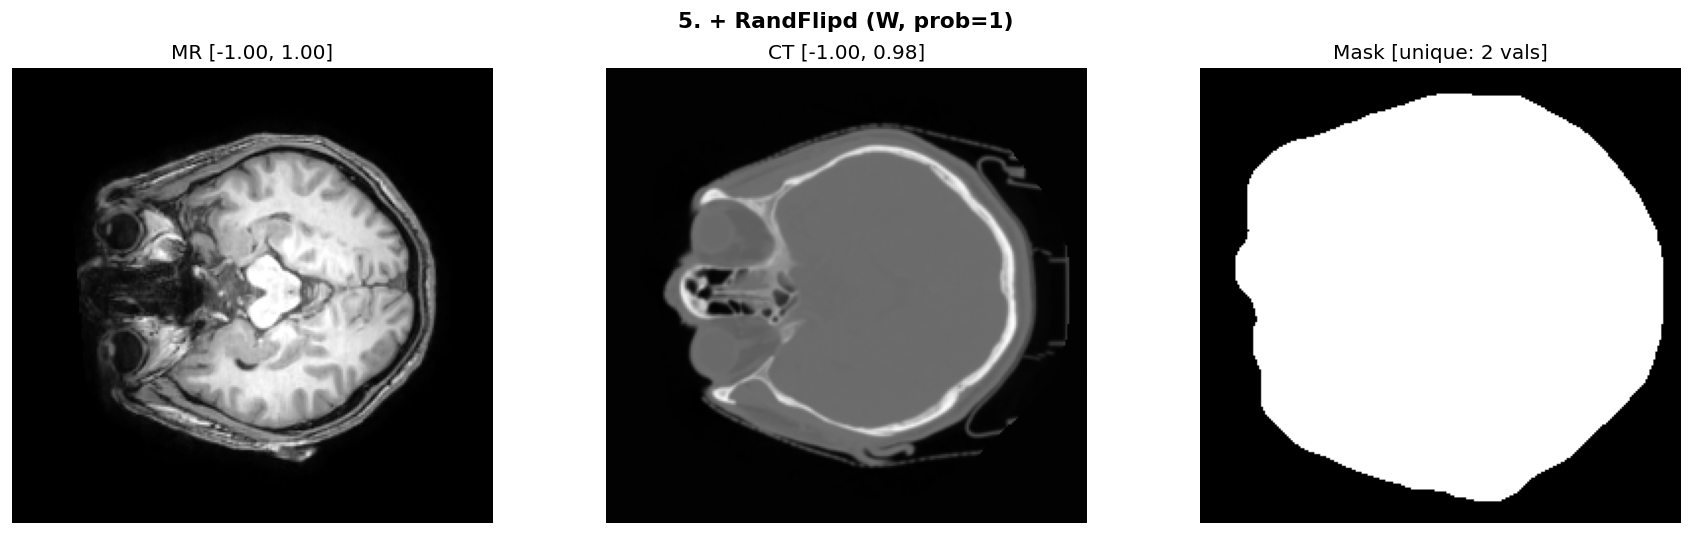

  MR shape: torch.Size([1, 231, 244, 163]), CT shape: torch.Size([1, 231, 244, 163])



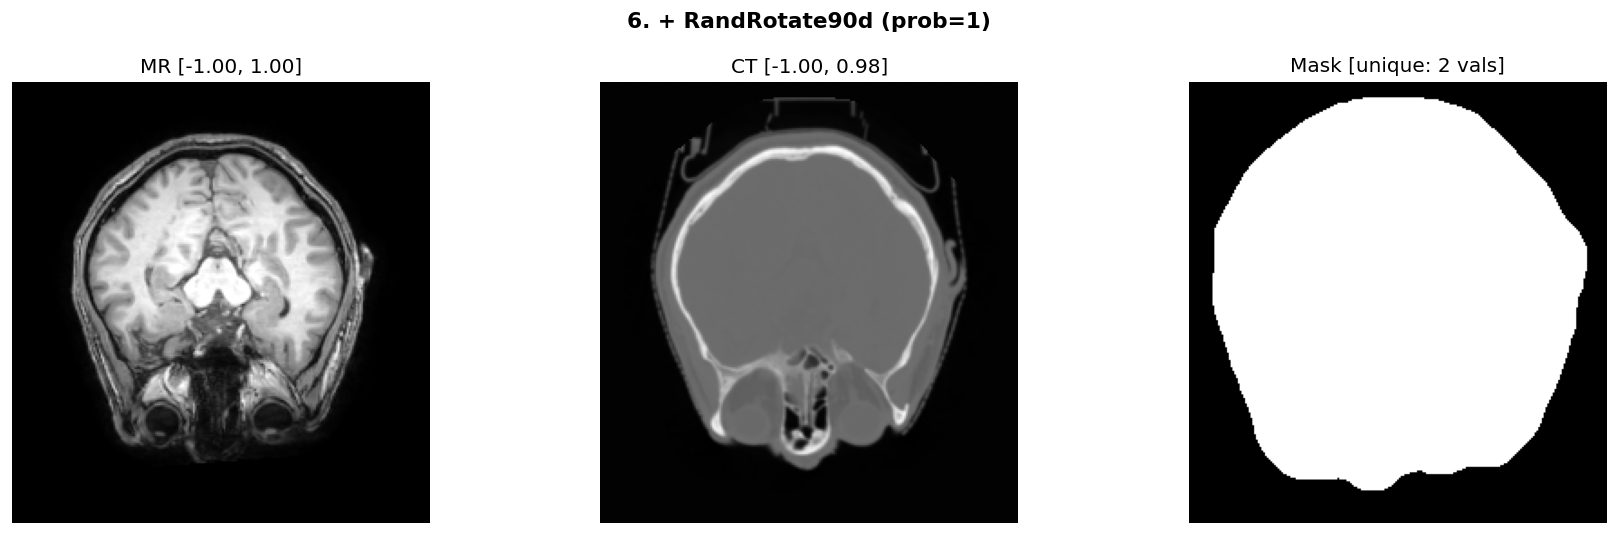

  MR shape: torch.Size([1, 244, 231, 163]), CT shape: torch.Size([1, 244, 231, 163])



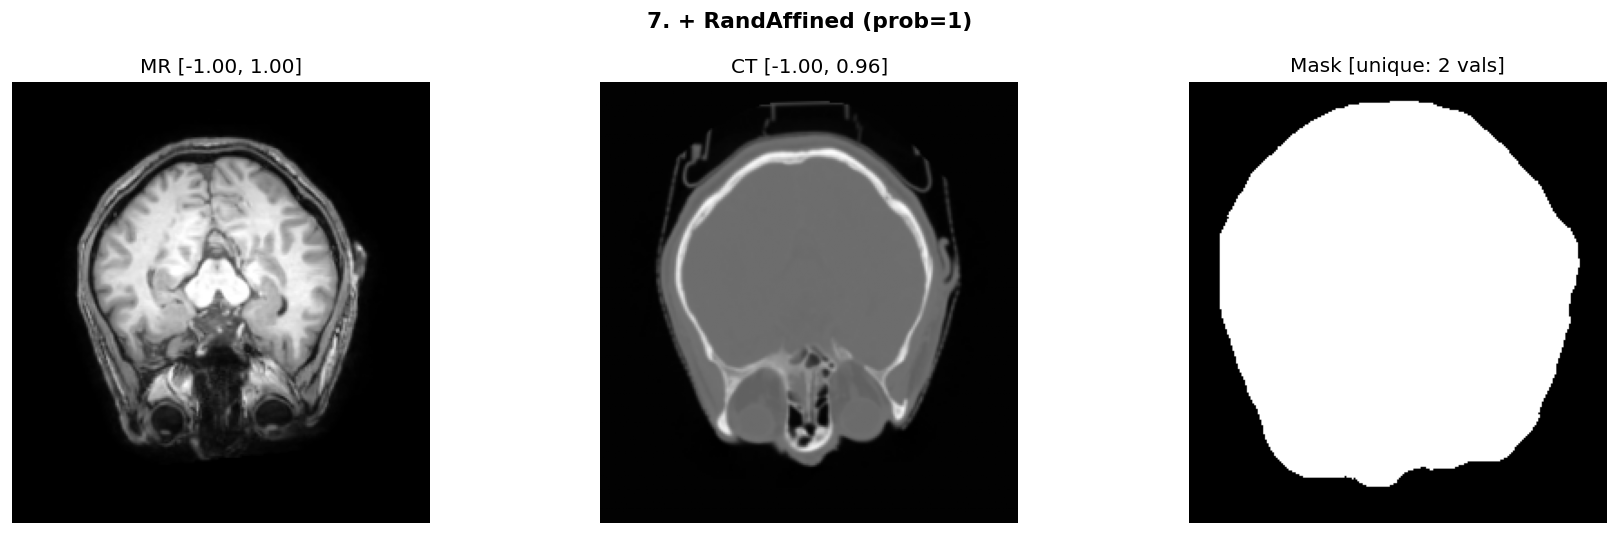

  MR shape: torch.Size([1, 244, 231, 163]), CT shape: torch.Size([1, 244, 231, 163])



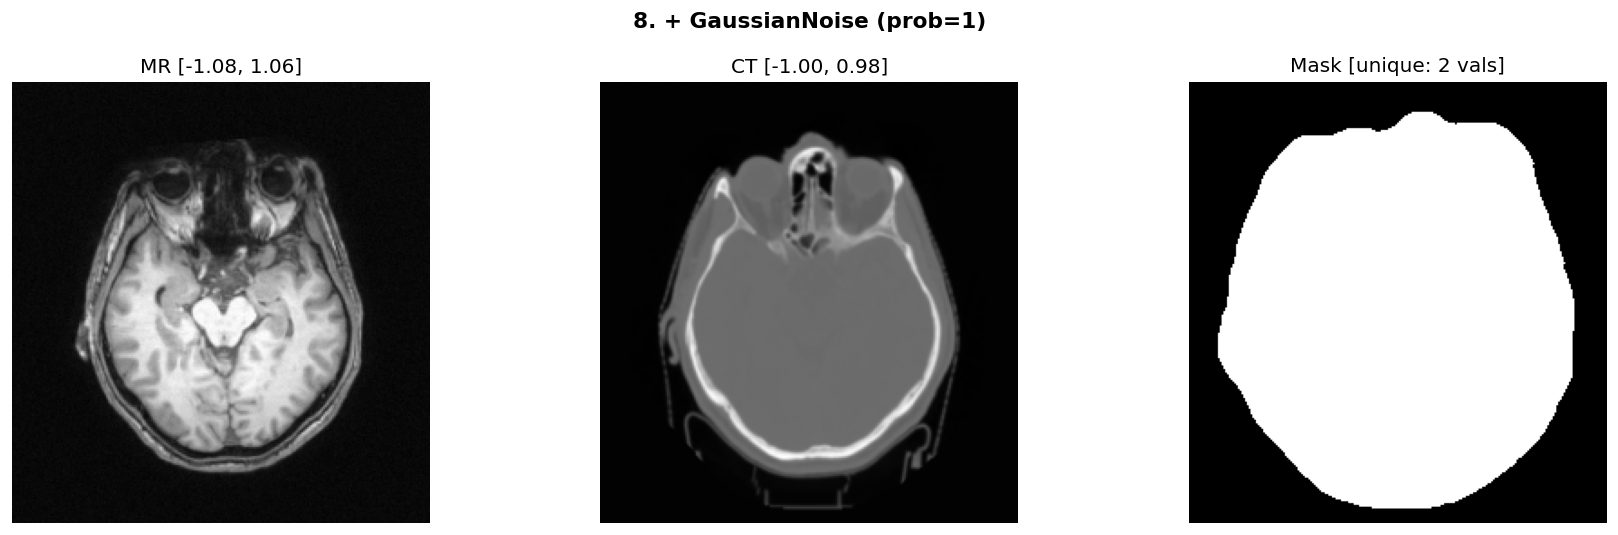

  MR shape: torch.Size([1, 244, 231, 163]), CT shape: torch.Size([1, 244, 231, 163])



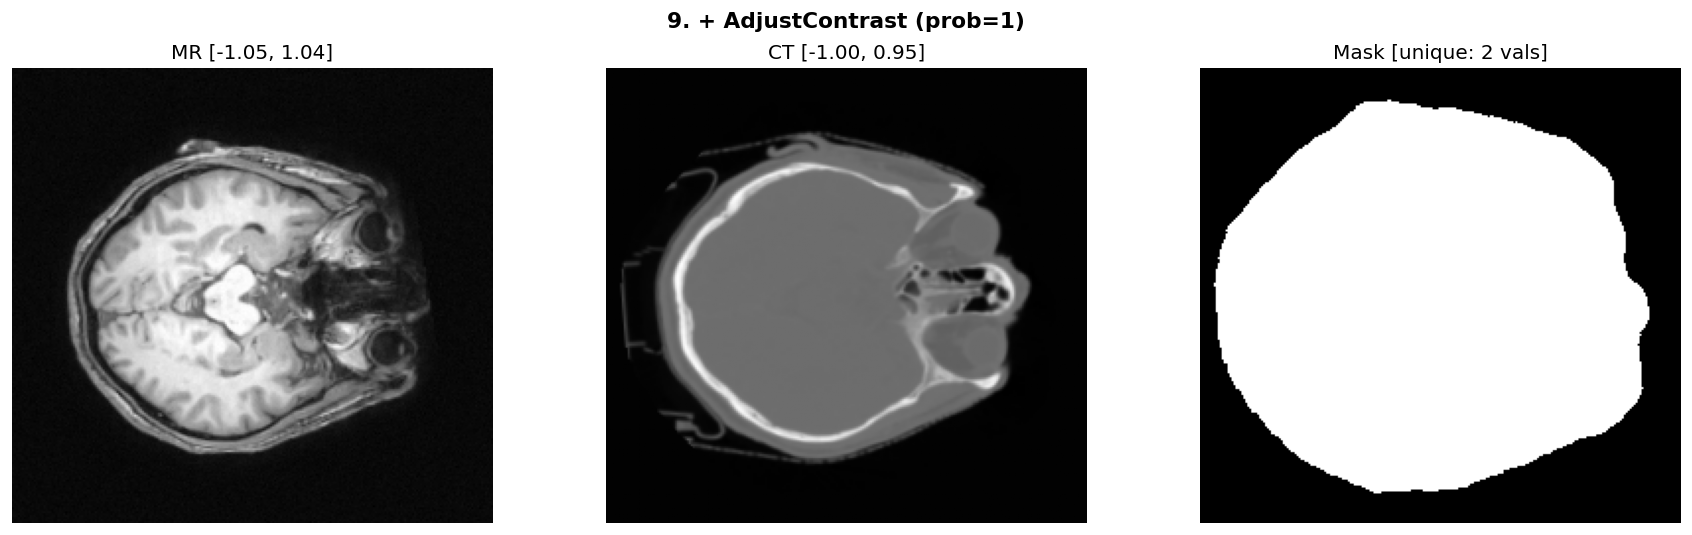

  MR shape: torch.Size([1, 231, 244, 163]), CT shape: torch.Size([1, 231, 244, 163])



In [9]:
# Apply each stage and visualize
for stage_name, stage_transform in stages:
    result = stage_transform(dict(transform_input))  # copy dict
    mr_vol = result["mr"]
    ct_vol = result["ct"]
    
    # Handle both 3D [H,W,D] and 4D [C,H,W,D]
    if mr_vol.ndim == 4:
        mr_s = mr_vol[0, :, :, s].numpy() if hasattr(mr_vol, 'numpy') else np.array(mr_vol[0, :, :, s])
        ct_s = ct_vol[0, :, :, s].numpy() if hasattr(ct_vol, 'numpy') else np.array(ct_vol[0, :, :, s])
    elif mr_vol.ndim == 3:
        mr_s = mr_vol[:, :, s].numpy() if hasattr(mr_vol, 'numpy') else np.array(mr_vol[:, :, s])
        ct_s = ct_vol[:, :, s].numpy() if hasattr(ct_vol, 'numpy') else np.array(ct_vol[:, :, s])
    else:
        print(f"  Unexpected shape: MR={mr_vol.shape}")
        continue
    
    has_mask_key = "mask" in result
    ncols = 3 if has_mask_key else 2
    fig, axes = plt.subplots(1, ncols, figsize=(5 * ncols, 4.5))
    axes[0].imshow(mr_s, cmap='gray'); axes[0].set_title(f'MR [{mr_s.min():.2f}, {mr_s.max():.2f}]')
    axes[1].imshow(ct_s, cmap='gray'); axes[1].set_title(f'CT [{ct_s.min():.2f}, {ct_s.max():.2f}]')
    if has_mask_key:
        mask_vol = result["mask"]
        if mask_vol.ndim == 4:
            mask_s = mask_vol[0, :, :, s].numpy() if hasattr(mask_vol, 'numpy') else np.array(mask_vol[0, :, :, s])
        else:
            mask_s = mask_vol[:, :, s].numpy() if hasattr(mask_vol, 'numpy') else np.array(mask_vol[:, :, s])
        axes[2].imshow(mask_s, cmap='gray'); axes[2].set_title(f'Mask [unique: {np.unique(mask_s).size} vals]')
    for ax in axes: ax.axis('off')
    plt.suptitle(stage_name, fontsize=13, fontweight='bold')
    plt.tight_layout(); plt.show()
    print(f"  MR shape: {mr_vol.shape}, CT shape: {ct_vol.shape}")
    print()

## 5. Full Dataset Output (from MonaiNiftiSliceDataset)
Test the actual dataset class with the full transform pipeline.

In [10]:
# Create dataset with a single patient for quick testing
train_transforms = get_monai_nifti_transforms(mode="train", target_size=TARGET_SIZE, use_body_mask=USE_BODY_MASK)
val_transforms = get_monai_nifti_transforms(mode="val", target_size=TARGET_SIZE, use_body_mask=USE_BODY_MASK)

# Use first 2 patients
test_files = all_files[:2]
train_ds = MonaiNiftiSliceDataset(data=test_files, transform=train_transforms, target_size=TARGET_SIZE, use_body_mask=USE_BODY_MASK)
val_ds = MonaiNiftiSliceDataset(data=test_files, transform=val_transforms, target_size=TARGET_SIZE, use_body_mask=USE_BODY_MASK)

print(f"Train dataset: {len(train_ds)} slices")
print(f"Val dataset:   {len(val_ds)} slices")

Pre-scanning NIfTI files to create slice map (using ALL slices)...
  Patient 1BA001: 163 slices
  Patient 1BA005: 164 slices
Total slices in dataset: 327
Body mask loading ENABLED - will load mask files for anatomically-focused training
Pre-scanning NIfTI files to create slice map (using ALL slices)...
  Patient 1BA001: 163 slices
  Patient 1BA005: 164 slices
Total slices in dataset: 327
Body mask loading ENABLED - will load mask files for anatomically-focused training
Train dataset: 327 slices
Val dataset:   327 slices


In [11]:
# Pick a middle slice
mid_idx = len(train_ds) // 2
print(f"Loading train sample at index {mid_idx}...")
train_sample = train_ds[mid_idx]
val_sample = val_ds[mid_idx]

mr_t = train_sample["mr"][0].numpy()
ct_t = train_sample["ct"][0].numpy()
mr_v = val_sample["mr"][0].numpy()
ct_v = val_sample["ct"][0].numpy()

has_mask_out = "mask" in train_sample

print(f"Train MR shape: {train_sample['mr'].shape}, range: [{mr_t.min():.3f}, {mr_t.max():.3f}]")
print(f"Train CT shape: {train_sample['ct'].shape}, range: [{ct_t.min():.3f}, {ct_t.max():.3f}]")
if has_mask_out:
    mask_t = train_sample["mask"][0].numpy()
    print(f"Train Mask shape: {train_sample['mask'].shape}, coverage: {mask_t.mean()*100:.1f}%")

Loading train sample at index 163...
Train MR shape: torch.Size([1, 256, 256]), range: [-1.000, 1.000]
Train CT shape: torch.Size([1, 256, 256]), range: [-0.987, -0.132]
Train Mask shape: torch.Size([1, 256, 256]), coverage: 19.3%


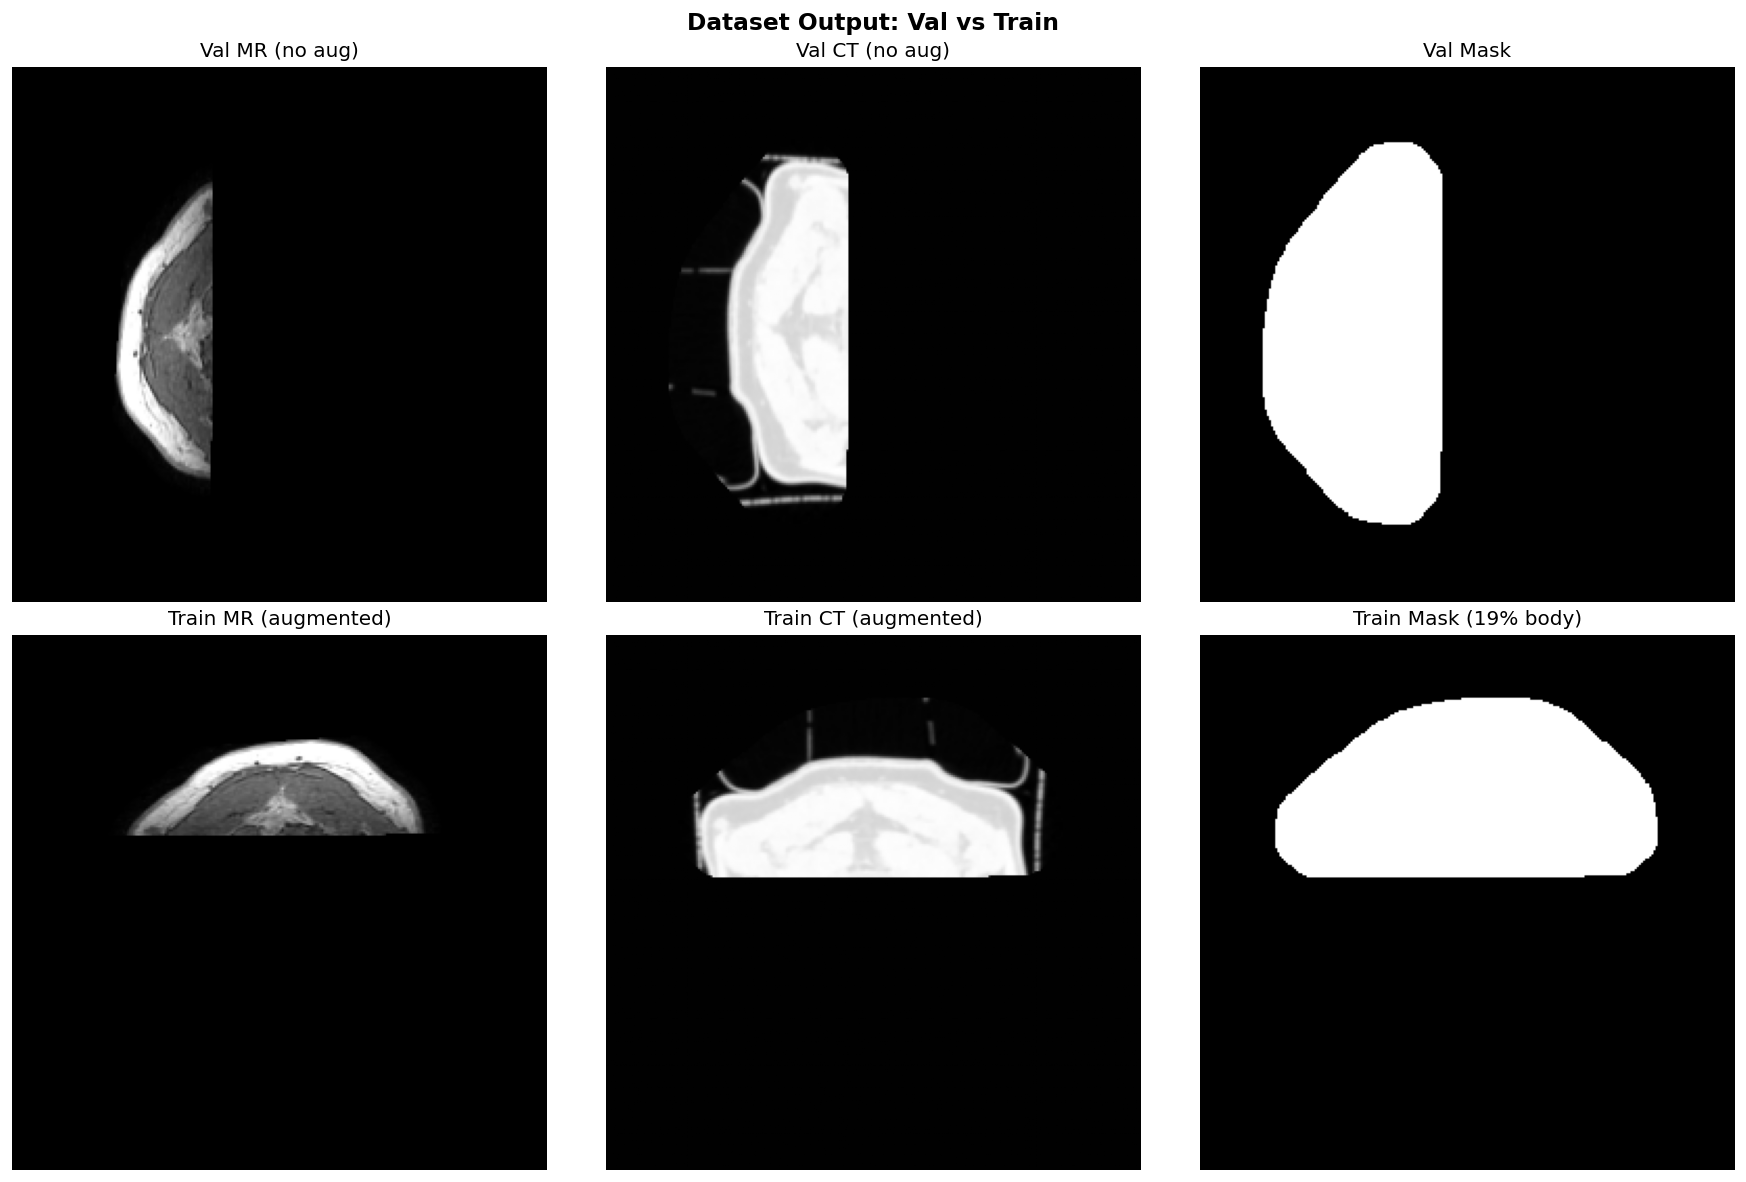

In [12]:
# Side-by-side: Val (no augmentation) vs Train (with augmentation)
nrows = 2
ncols = 3 if has_mask_out else 2
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 5 * nrows))

# Row 0: Val (base transforms only)
axes[0, 0].imshow(mr_v, cmap='gray'); axes[0, 0].set_title('Val MR (no aug)')
axes[0, 1].imshow(ct_v, cmap='gray'); axes[0, 1].set_title('Val CT (no aug)')
if has_mask_out:
    axes[0, 2].imshow(val_sample["mask"][0].numpy(), cmap='gray'); axes[0, 2].set_title('Val Mask')

# Row 1: Train (with augmentation)
axes[1, 0].imshow(mr_t, cmap='gray'); axes[1, 0].set_title('Train MR (augmented)')
axes[1, 1].imshow(ct_t, cmap='gray'); axes[1, 1].set_title('Train CT (augmented)')
if has_mask_out:
    axes[1, 2].imshow(mask_t, cmap='gray'); axes[1, 2].set_title(f'Train Mask ({mask_t.mean()*100:.0f}% body)')

for ax_row in axes:
    for ax in ax_row: ax.axis('off')
plt.suptitle('Dataset Output: Val vs Train', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()

## 6. Multiple Augmentation Samples
Show the same slice augmented multiple times to see the randomness.

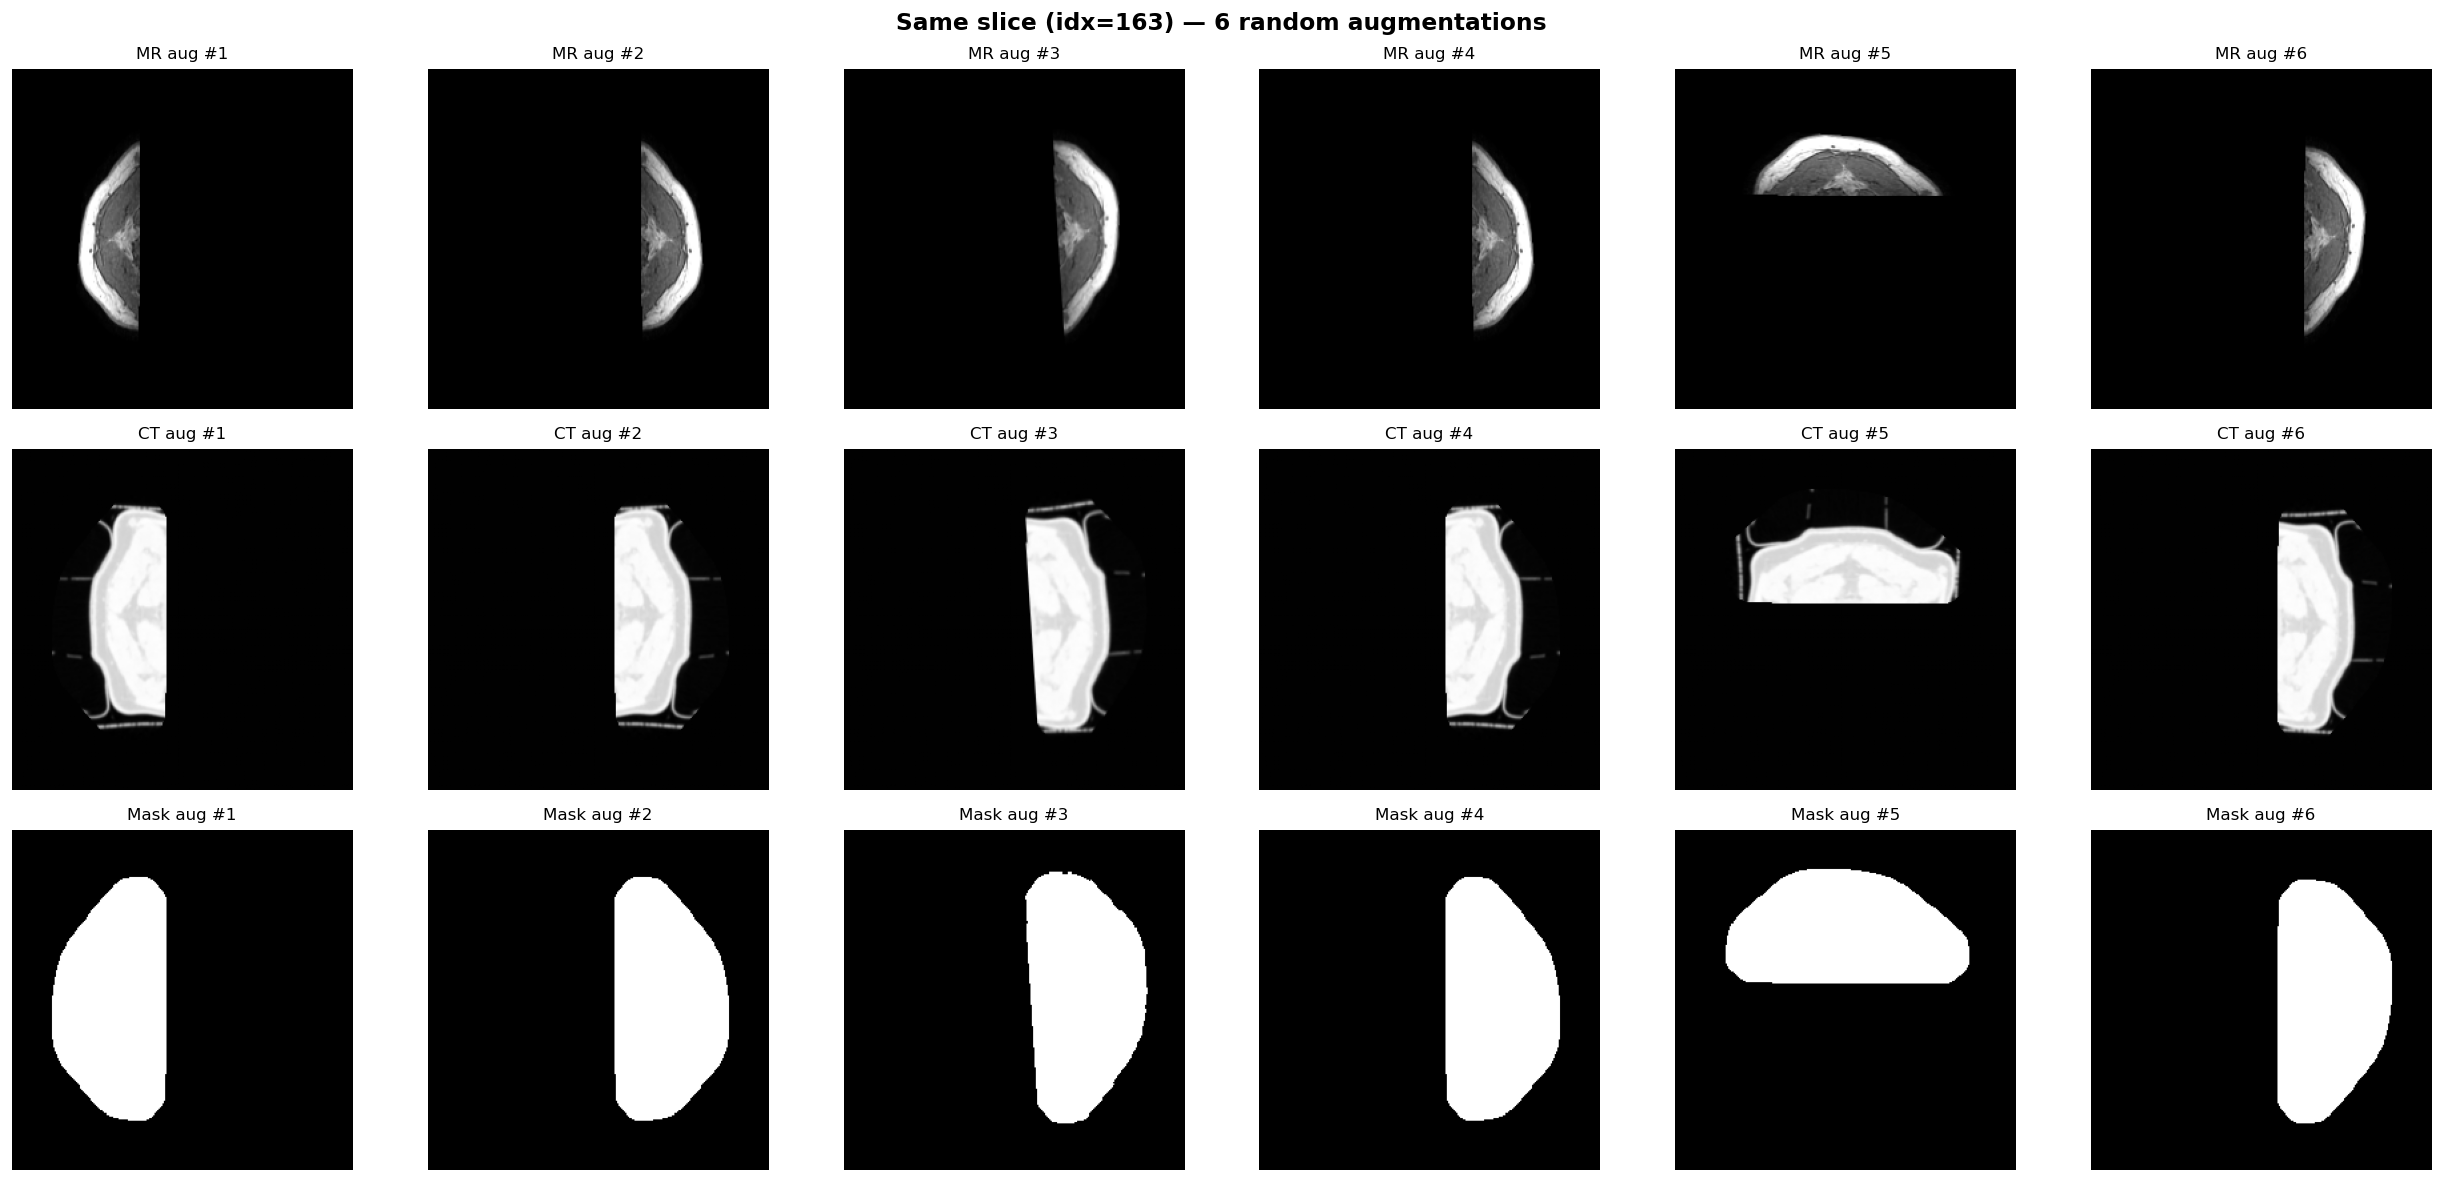

In [13]:
N_SAMPLES = 6
fig, axes = plt.subplots(3 if has_mask_out else 2, N_SAMPLES, figsize=(3.5 * N_SAMPLES, 10 if has_mask_out else 7))

for i in range(N_SAMPLES):
    s_out = train_ds[mid_idx]  # Random augmentation each time
    axes[0, i].imshow(s_out["mr"][0].numpy(), cmap='gray')
    axes[0, i].set_title(f'MR aug #{i+1}', fontsize=10)
    axes[1, i].imshow(s_out["ct"][0].numpy(), cmap='gray')
    axes[1, i].set_title(f'CT aug #{i+1}', fontsize=10)
    if has_mask_out:
        axes[2, i].imshow(s_out["mask"][0].numpy(), cmap='gray')
        axes[2, i].set_title(f'Mask aug #{i+1}', fontsize=10)

for ax_row in axes:
    for ax in ax_row: ax.axis('off')
plt.suptitle(f'Same slice (idx={mid_idx}) — {N_SAMPLES} random augmentations', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()

## 7. Mask Overlay Check
Verify the mask aligns with MR/CT after all transforms.

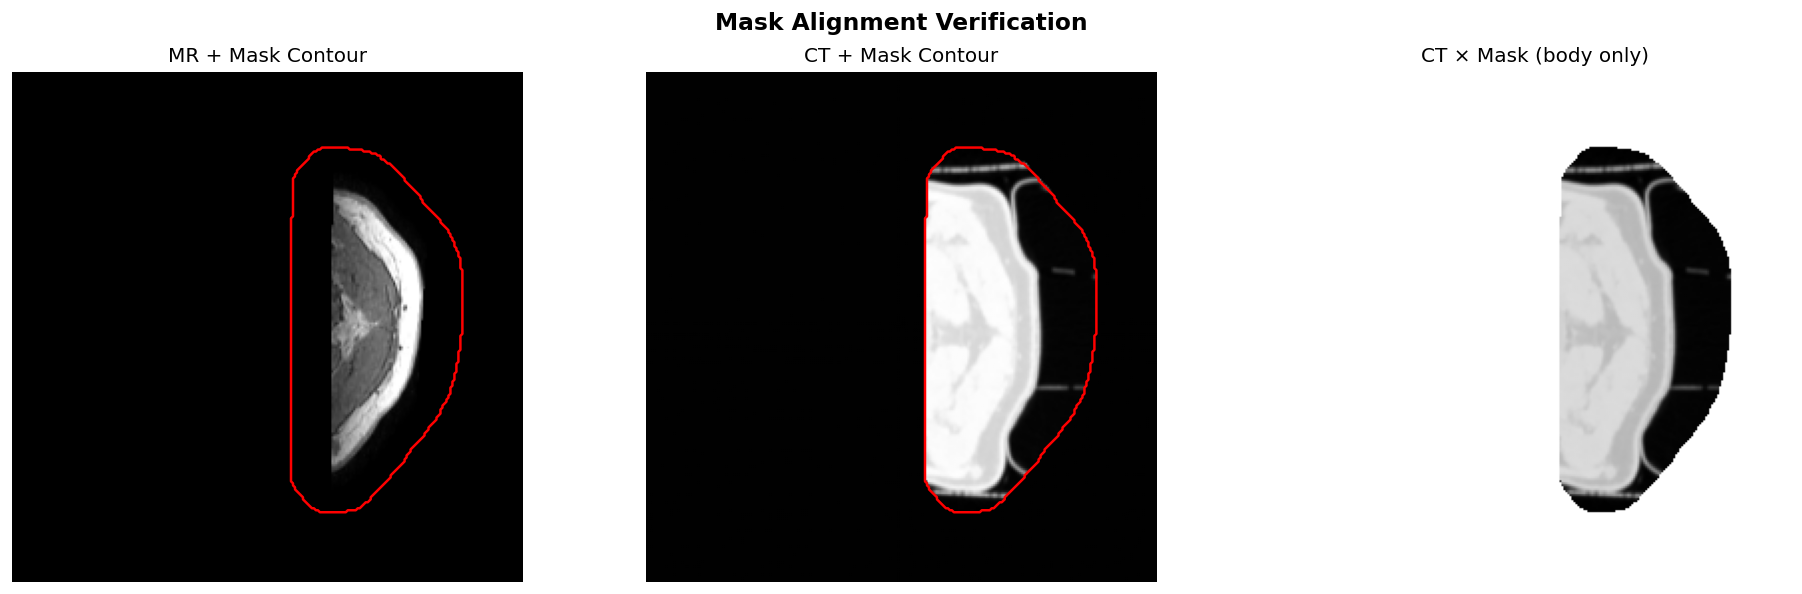

In [14]:
if has_mask_out:
    fig, axes = plt.subplots(1, 3, figsize=(16, 5))
    out = train_ds[mid_idx]
    mr_img = out["mr"][0].numpy()
    ct_img = out["ct"][0].numpy()
    mask_img = out["mask"][0].numpy()
    
    # MR with mask contour
    axes[0].imshow(mr_img, cmap='gray')
    axes[0].contour(mask_img, levels=[0.5], colors='red', linewidths=1.5)
    axes[0].set_title('MR + Mask Contour')
    
    # CT with mask contour
    axes[1].imshow(ct_img, cmap='gray')
    axes[1].contour(mask_img, levels=[0.5], colors='red', linewidths=1.5)
    axes[1].set_title('CT + Mask Contour')
    
    # CT masked (body only)
    ct_masked = ct_img * mask_img
    axes[2].imshow(ct_masked, cmap='gray')
    axes[2].set_title('CT × Mask (body only)')
    
    for ax in axes: ax.axis('off')
    plt.suptitle('Mask Alignment Verification', fontsize=14, fontweight='bold')
    plt.tight_layout(); plt.show()
else:
    print("No mask available — skipping overlay check.")

## 8. Intensity Distribution

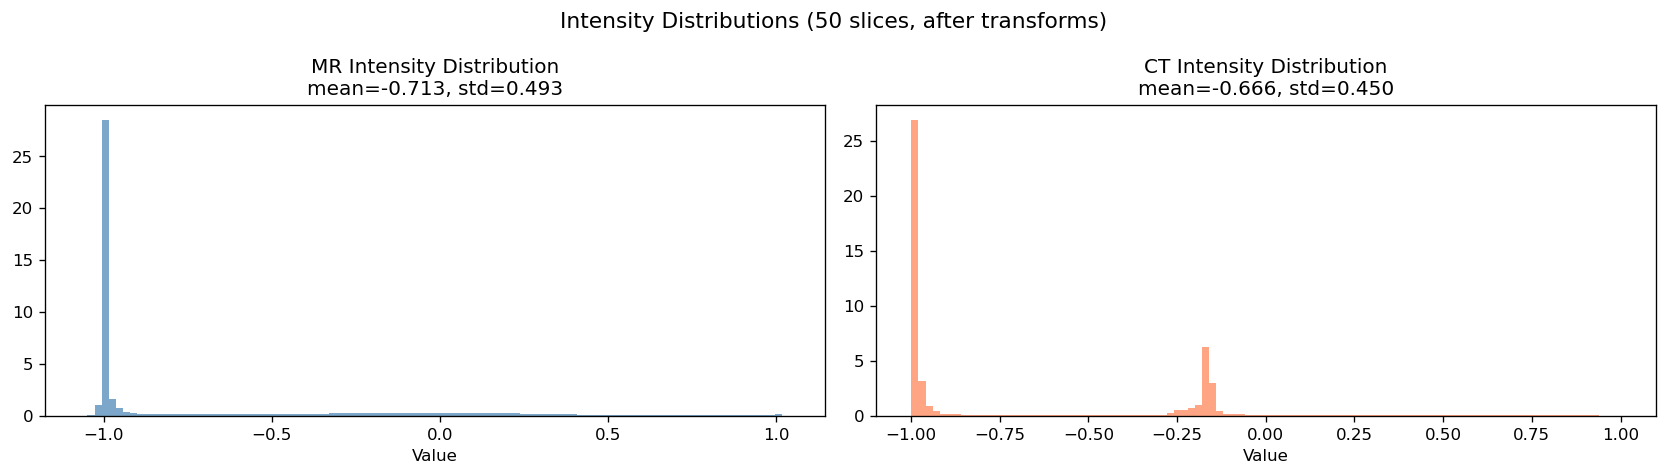

In [15]:
# Sample a few slices and plot histograms
mr_vals, ct_vals = [], []
n_hist = min(50, len(train_ds))
indices = np.linspace(0, len(train_ds)-1, n_hist, dtype=int)

for idx in indices:
    out = train_ds[idx]
    mr_vals.append(out["mr"].numpy().flatten())
    ct_vals.append(out["ct"].numpy().flatten())

mr_all = np.concatenate(mr_vals)
ct_all = np.concatenate(ct_vals)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(mr_all, bins=100, alpha=0.7, color='steelblue', density=True)
axes[0].set_title(f'MR Intensity Distribution\nmean={mr_all.mean():.3f}, std={mr_all.std():.3f}'); axes[0].set_xlabel('Value')
axes[1].hist(ct_all, bins=100, alpha=0.7, color='coral', density=True)
axes[1].set_title(f'CT Intensity Distribution\nmean={ct_all.mean():.3f}, std={ct_all.std():.3f}'); axes[1].set_xlabel('Value')
plt.suptitle(f'Intensity Distributions ({n_hist} slices, after transforms)', fontsize=13)
plt.tight_layout(); plt.show()

## 9. DataLoader Test
Quick sanity check that batching works correctly.

In [16]:
from torch.utils.data import DataLoader

loader = DataLoader(train_ds, batch_size=4, shuffle=True, num_workers=0)
batch = next(iter(loader))

print(f"Batch MR shape: {batch['mr'].shape}")
print(f"Batch CT shape: {batch['ct'].shape}")
if 'mask' in batch:
    print(f"Batch Mask shape: {batch['mask'].shape}")
print(f"MR dtype: {batch['mr'].dtype}, CT dtype: {batch['ct'].dtype}")
print(f"MR range: [{batch['mr'].min():.3f}, {batch['mr'].max():.3f}]")
print(f"CT range: [{batch['ct'].min():.3f}, {batch['ct'].max():.3f}]")
print("\n✅ DataLoader works correctly!")

Batch MR shape: torch.Size([4, 1, 256, 256])
Batch CT shape: torch.Size([4, 1, 256, 256])
Batch Mask shape: torch.Size([4, 1, 256, 256])
MR dtype: torch.float32, CT dtype: torch.float32
MR range: [-1.000, 1.000]
CT range: [-0.998, 0.986]

✅ DataLoader works correctly!


## 10. Numerical Comparison: loader.py vs loader2.py
Compare the exact output of both loaders to find any data differences.

In [17]:
"""
Compare loader.py (current, no CacheDataset) vs loader2.py (previous, with CacheDataset)
using VAL transforms (deterministic only) to isolate any data pipeline differences.
"""
import importlib
import loader as loader_new
import loader2 as loader_old
importlib.reload(loader_new)
importlib.reload(loader_old)

# Use first 2 patients, val mode (deterministic - no random augmentation)
test_files = all_files[:2]

# --- loader.py (current) ---
val_tf_new = loader_new.get_monai_nifti_transforms(mode="val", target_size=TARGET_SIZE, use_body_mask=USE_BODY_MASK)
ds_new = loader_new.MonaiNiftiSliceDataset(data=test_files, transform=val_tf_new, target_size=TARGET_SIZE, use_body_mask=USE_BODY_MASK)

# --- loader2.py (previous, good performance) ---
val_tf_old = loader_old.get_monai_nifti_transforms(mode="val", target_size=TARGET_SIZE, use_body_mask=USE_BODY_MASK)
ds_old = loader_old.MonaiNiftiSliceDataset(data=test_files, transform=val_tf_old, target_size=TARGET_SIZE, use_body_mask=USE_BODY_MASK)

print(f"loader.py  dataset length: {len(ds_new)}")
print(f"loader2.py dataset length: {len(ds_old)}")

# Compare multiple slices
diffs_mr, diffs_ct, diffs_mask = [], [], []
test_indices = [0, len(ds_new)//4, len(ds_new)//2, 3*len(ds_new)//4, len(ds_new)-1]

for idx in test_indices:
    out_new = ds_new[idx]
    out_old = ds_old[idx]
    
    mr_diff = (out_new["mr"] - out_old["mr"]).abs()
    ct_diff = (out_new["ct"] - out_old["ct"]).abs()
    
    diffs_mr.append(mr_diff.max().item())
    diffs_ct.append(ct_diff.max().item())
    
    print(f"\n--- Slice idx={idx} ---")
    print(f"  MR  new: [{out_new['mr'].min():.6f}, {out_new['mr'].max():.6f}], shape={out_new['mr'].shape}")
    print(f"  MR  old: [{out_old['mr'].min():.6f}, {out_old['mr'].max():.6f}], shape={out_old['mr'].shape}")
    print(f"  MR  max diff: {mr_diff.max().item():.8f},  mean diff: {mr_diff.mean().item():.8f}")
    print(f"  CT  new: [{out_new['ct'].min():.6f}, {out_new['ct'].max():.6f}]")
    print(f"  CT  old: [{out_old['ct'].min():.6f}, {out_old['ct'].max():.6f}]")
    print(f"  CT  max diff: {ct_diff.max().item():.8f},  mean diff: {ct_diff.mean().item():.8f}")
    
    if "mask" in out_new and "mask" in out_old:
        mask_diff = (out_new["mask"] - out_old["mask"]).abs()
        diffs_mask.append(mask_diff.max().item())
        print(f"  Mask new coverage: {out_new['mask'].mean()*100:.1f}%, old coverage: {out_old['mask'].mean()*100:.1f}%")
        print(f"  Mask max diff: {mask_diff.max().item():.6f}")

print(f"\n{'='*60}")
print(f"SUMMARY across {len(test_indices)} slices:")
print(f"  Max MR diff:   {max(diffs_mr):.8f}")
print(f"  Max CT diff:   {max(diffs_ct):.8f}")
if diffs_mask:
    print(f"  Max Mask diff:  {max(diffs_mask):.8f}")
if max(diffs_mr) < 1e-5 and max(diffs_ct) < 1e-5:
    print(f"\n  Data is IDENTICAL between both loaders (val mode)")
else:
    print(f"\n  Data DIFFERS between loaders!")

Pre-scanning NIfTI files to create slice map (using ALL slices)...
  Patient 1BA001: 163 slices
  Patient 1BA005: 164 slices
Total slices in dataset: 327
Body mask loading ENABLED - will load mask files for anatomically-focused training
Pre-scanning NIfTI files to create slice map (using ALL slices)...
  Patient 1BA001: 163 slices
  Patient 1BA005: 164 slices
Total slices in dataset: 327
Body mask loading ENABLED - will load mask files for anatomically-focused training


Loading dataset: 100%|██████████| 2/2 [00:00<00:00,  2.36it/s]


Volume caching ENABLED: cache_rate=1.00 (2/2 volumes)
loader.py  dataset length: 327
loader2.py dataset length: 327

--- Slice idx=0 ---
  MR  new: [-1.000000, 0.791089], shape=torch.Size([1, 256, 256])
  MR  old: [-1.000000, 0.791089], shape=torch.Size([1, 256, 256])
  MR  max diff: 0.00000000,  mean diff: 0.00000000
  CT  new: [-0.984449, 0.523483]
  CT  old: [-0.984449, 0.523483]
  CT  max diff: 0.00000000,  mean diff: 0.00000000
  Mask new coverage: 16.9%, old coverage: 16.9%
  Mask max diff: 0.000000

--- Slice idx=81 ---
  MR  new: [-1.000000, 1.000000], shape=torch.Size([1, 256, 256])
  MR  old: [-1.000000, 1.000000], shape=torch.Size([1, 256, 256])
  MR  max diff: 0.00000000,  mean diff: 0.00000000
  CT  new: [-0.998954, 0.973280]
  CT  old: [-0.998954, 0.973280]
  CT  max diff: 0.00000000,  mean diff: 0.00000000
  Mask new coverage: 62.2%, old coverage: 62.2%
  Mask max diff: 0.000000

--- Slice idx=163 ---
  MR  new: [-1.000000, 1.000000], shape=torch.Size([1, 256, 256])
  MR

In [18]:
import time

# Time a single __getitem__ call for each loader
test_idx = list(range(0, 30))

# loader.py (NO CacheDataset - loads from disk every time)
t0 = time.time()
for i in test_idx:
    _ = ds_new[i]
t_new = time.time() - t0

# loader2.py (WITH CacheDataset - data already in RAM)
t0 = time.time()
for i in test_idx:
    _ = ds_old[i]
t_old = time.time() - t0

print(f"loader.py  (no cache):  {t_new:.3f}s for {len(test_idx)} samples  ({t_new/len(test_idx)*1000:.1f} ms/sample)")
print(f"loader2.py (cached):    {t_old:.3f}s for {len(test_idx)} samples  ({t_old/len(test_idx)*1000:.1f} ms/sample)")
print(f"\nSpeedup factor: {t_new/t_old:.1f}x")

# Estimate epoch time
total_slices = 303 * 163  # ~49K slices full dataset
epoch_new = t_new / len(test_idx) * total_slices / 4  # 4 workers
epoch_old = t_old / len(test_idx) * total_slices / 4
print(f"\nEstimated epoch time (303 patients, 4 workers):")
print(f"  loader.py  (no cache):  {epoch_new/60:.1f} min/epoch")
print(f"  loader2.py (cached):    {epoch_old/60:.1f} min/epoch")

loader.py  (no cache):  12.164s for 30 samples  (405.5 ms/sample)
loader2.py (cached):    0.036s for 30 samples  (1.2 ms/sample)

Speedup factor: 338.5x

Estimated epoch time (303 patients, 4 workers):
  loader.py  (no cache):  83.4 min/epoch
  loader2.py (cached):    0.2 min/epoch


In [19]:
# Verify the fix: reload loader.py and test speed
importlib.reload(loader_new)
val_tf_fixed = loader_new.get_monai_nifti_transforms(mode="val", target_size=TARGET_SIZE, use_body_mask=USE_BODY_MASK)
ds_fixed = loader_new.MonaiNiftiSliceDataset(data=test_files, transform=val_tf_fixed, target_size=TARGET_SIZE, use_body_mask=USE_BODY_MASK)

t0 = time.time()
for i in range(30):
    _ = ds_fixed[i]
t_fixed = time.time() - t0

print(f"\nFixed loader.py (with CacheDataset): {t_fixed:.3f}s for 30 samples ({t_fixed/30*1000:.1f} ms/sample)")
print(f"Original loader2.py:                 {t_old:.3f}s for 30 samples ({t_old/30*1000:.1f} ms/sample)")

# Verify data is still identical
out_fixed = ds_fixed[81]
out_ref = ds_old[81]
mr_diff = (out_fixed["mr"] - out_ref["mr"]).abs().max().item()
ct_diff = (out_fixed["ct"] - out_ref["ct"]).abs().max().item()
print(f"\nData check vs loader2.py: MR max diff={mr_diff:.8f}, CT max diff={ct_diff:.8f}")

Pre-scanning NIfTI files to create slice map (using ALL slices)...
  Patient 1BA001: 163 slices
  Patient 1BA005: 164 slices
Total slices in dataset: 327
Body mask loading ENABLED - will load mask files for anatomically-focused training


Loading dataset: 100%|██████████| 2/2 [00:00<00:00,  2.43it/s]

Volume caching ENABLED: cache_rate=1.00 (2/2 volumes)

Fixed loader.py (with CacheDataset): 0.031s for 30 samples (1.0 ms/sample)
Original loader2.py:                 0.036s for 30 samples (1.2 ms/sample)

Data check vs loader2.py: MR max diff=0.00000000, CT max diff=0.00000000
